In [ ]:
#!pip install scikit-learn
from sklearn.preprocessing import StandardScaler

In [ ]:
#!pip install -q tensorflow==2.8.0
import tensorflow as tf
import numpy as np #numpy is the numerical computing package in python
from tensorflow.keras.optimizers import SGD
print(tf.__version__)

2.17.1


In [ ]:
import torch
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, Concatenate
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers
from tensorflow.keras.losses import Loss
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, TensorBoard, ReduceLROnPlateau, TerminateOnNaN
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import Callback
import datetime
import statsmodels.api as sm
import re


In [ ]:
## load the data and data pre-processing
import numpy as np
from sklearn.preprocessing import StandardScaler
import pandas as pd
df = pd.read_csv('/content/ACTG175_data.csv')
#Listwise Deletion
df = df.dropna()

####X
# All binary or close to categorical
c1 = ["hemo", "homo", "drugs", "oprior", "z30", "race", "gender", "str2", "symptom", "karnof"] #Guess Karnofsky score also needs to be standardlized!


c2 = ["age", "wtkg", "cd40", "cd80","preanti"]

# Resclaing c2
scaler = StandardScaler()

# Fit the scaler to the data and transform it
df[c2] = scaler.fit_transform(df[c2])
# Standardize the "karnof" column
df["karnof"] = scaler.fit_transform(df[["karnof"]])

# Combine them into one vector of column names
combined_columns = c1 + c2

x = df[combined_columns]
####Y, also need to be scaled.
y = torch.load('fs_2.pth').float()

#### t
t = df['treat']




<ipython-input-4-ff80873e7c19>:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  y = torch.load('fs_2.pth').float()


In [ ]:
y

tensor([[ 0.3765],
        [-0.7338],
        [ 0.3905],
        ...,
        [ 1.7516],
        [ 0.4806],
        [-1.5837]])

In [ ]:
y = scaler.fit_transform(y)

In [ ]:
y

array([[ 0.37550349],
       [-0.74142947],
       [ 0.38956499],
       ...,
       [ 1.75896767],
       [ 0.48021969],
       [-1.59650992]])

In [ ]:
x

,hemo,homo,drugs,oprior,z30,race,gender,str2,symptom,karnof,age,wtkg,cd40,cd80,preanti
0,0,0,0,0,0,0,0,0,0,0.743877,1.462138,1.195733,0.573436,-0.893028,-0.833558
2,0,1,1,0,1,0,1,1,0,-1.058078,1.115563,1.087467,-0.248048,2.217113,0.687785
4,0,1,0,0,1,0,1,1,0,0.743877,0.884514,-0.644795,1.275120,-0.261443,2.075716
5,0,1,1,0,1,0,1,1,0,0.743877,1.231088,1.123555,-1.026746,-0.282218,1.707753
6,0,1,0,0,1,0,1,1,0,0.743877,-0.501784,-0.139552,-0.949732,-0.598011,1.167643
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2129,1,0,0,0,1,0,1,1,0,0.743877,-2.234656,-0.937515,-0.479091,-0.934579,0.786770
2130,1,0,0,0,1,0,1,1,0,0.743877,-1.194933,0.255897,0.967063,-0.747597,1.113848
2131,1,0,0,0,0,0,0,0,0,0.743877,-1.772557,-0.189644,1.095420,1.521123,-0.833558
2136,1,1,0,0,1,1,1,1,0,-1.058078,2.039762,-0.392174,0.547764,0.820978,0.786770


In [ ]:
## potential outcome mu_0, mu_1 caluculation
import statsmodels.api as sm

# Define the outcome variable, treatment variable, and covariates
Y = y
T = t
X = x  # Replace with actual column names

# Add a constant to the covariates matrix
X = sm.add_constant(X)

# Fit the regression model
model = sm.OLS(Y, sm.add_constant(pd.concat([T, X], axis=1))).fit()

# Display the summary of the model
model.summary()



<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.375
Model:                            OLS   Adj. R-squared:                  0.368
Method:                 Least Squares   F-statistic:                     49.76
Date:                Mon, 20 Jan 2025   Prob (F-statistic):          5.06e-123
Time:                        14:20:56   Log-Likelihood:                -1588.5
No. Observations:                1342   AIC:                             3211.
Df Residuals:                    1325   BIC:                             3299.
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
treat          0.3373      0.051      6.585      0.000       0.237       0.438
const         -0.0966      0.084     -1.144      0.253      -0.262       0.069
hemo          -0.2198      0.107     -2.060      0.040      -0.429      -0.011
homo           0.0078      0.079      0.098      0.922      -0.147       0.163
drugs          0.0502      0.072      0.699      0.485      -0.091       0.191
oprior        -0.3752      0.158     -2.380      0.017      -0.684      -0.066
z30           -0.0549      0.113     -0.487      0.627      -0.276       0.167
race          -0.1554      0.054     -2.867      0.004      -0.262      -0.049
gender         0.0573      0.090      0.635      0.526      -0.120       0.235
str2          -0.1745      0.118     -1.477      0.140      -0.406       0.057
symptom       -0.1127      0.059     -1.908      0.057      -0.229       0.003
karnof         0.0414      0.022      1.861      0.063      -0.002       0.085
age           -0.0435      0.023     -1.890      0.059      -0.089       0.002
wtkg           0.0174      0.023      0.743      0.457      -0.029       0.063
cd40           0.5545      0.023     24.315      0.000       0.510       0.599
cd80          -0.0647      0.023     -2.860      0.004      -0.109      -0.020
preanti       -0.0230      0.031     -0.735      0.463      -0.085       0.038
==============================================================================
Omnibus:                      161.487   Durbin-Watson:                   1.923
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              350.098
Skew:                           0.712   Prob(JB):                     9.49e-77
Kurtosis:                       5.057   Cond. No.                         16.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
# Predict potential outcomes for treated (mu_1) and control (mu_0)
X1 = sm.add_constant(pd.concat([pd.Series(1, index=X.index, name='T'), X], axis=1))
X0 = sm.add_constant(pd.concat([pd.Series(0, index=X.index, name='T'), X], axis=1))

mu_1 = model.predict(X1)
mu_0 = model.predict(X0)

# Convert to float32
mu_1 = torch.tensor(mu_1.values, dtype=torch.float32).numpy()
mu_0 = torch.tensor(mu_0.values, dtype=torch.float32).numpy()

In [ ]:
#true_ite
true_ite= mu_1 - mu_0
true_ite

array([0.33731896, 0.33731893, 0.33731893, ..., 0.33731893, 0.33731896,
       0.3373189 ], dtype=float32)

In [ ]:
mu_1.dtype

dtype('float32')

In [ ]:
###transfer x,y, t all into tensor, back to ndarray type!
x_values = df[combined_columns].values
x = torch.tensor(x_values, dtype=torch.float32).numpy()

t_values = df['treat'].values
t = torch.tensor(t_values, dtype=torch.float32).numpy()

In [ ]:
data = {'x': x, 't': t, 'y': y, 'mu_0': mu_0, 'mu_1':mu_1}
data['t']=data['t'].reshape(-1,1) #we're just padding one dimensional vectors with an additional dimension
data['y']=data['y'].reshape(-1,1)

#Rescaling y between 0 and 1 often makes training of DL regressors easier!
data['y_scaler'] = StandardScaler().fit(data['y'])
data['ys'] = data['y_scaler'].transform(data['y'])

In [ ]:
data['ys']

array([[ 0.37550349],
       [-0.74142947],
       [ 0.38956499],
       ...,
       [ 1.75896767],
       [ 0.48021969],
       [-1.59650992]])

In [ ]:
data['x']

array([[ 0.        ,  0.        ,  0.        , ...,  0.57343566,
        -0.8930276 , -0.83355826],
       [ 0.        ,  1.        ,  1.        , ..., -0.24804819,
         2.2171133 ,  0.68778545],
       [ 0.        ,  1.        ,  0.        , ...,  1.2751198 ,
        -0.26144254,  2.0757158 ],
       ...,
       [ 1.        ,  0.        ,  0.        , ...,  1.0954202 ,
         1.5211232 , -0.83355826],
       [ 1.        ,  1.        ,  0.        , ...,  0.5477643 ,
         0.8209779 ,  0.7867696 ],
       [ 1.        ,  0.        ,  0.        , ..., -1.617188  ,
         0.00656559, -0.83355826]], dtype=float32)

In [ ]:
import tensorflow as tf
import numpy as np
import datetime
#Colab command to allow us to run Colab in TF2
%load_ext tensorboard

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


In [ ]:
from tensorflow.keras.callbacks import Callback

def pdist2sq(x,y):
    x2 = tf.reduce_sum(x ** 2, axis=-1, keepdims=True)
    y2 = tf.reduce_sum(y ** 2, axis=-1, keepdims=True)
    dist = x2 + tf.transpose(y2, (1, 0)) - 2. * x @ tf.transpose(y, (1, 0))
    return dist

'''
def pdist2sq(A, B):
    #helper for PEHEnn
    #calculates squared euclidean distance between rows of two matrices
    #https://gist.github.com/mbsariyildiz/34cdc26afb630e8cae079048eef91865
    # squared norms of each row in A and B
    na = tf.reduce_sum(tf.square(A), 1)
    nb = tf.reduce_sum(tf.square(B), 1)
    # na as a row and nb as a column vectors
    na = tf.reshape(na, [-1, 1])
    nb = tf.reshape(nb, [1, -1])
    # return pairwise euclidean difference matrix
    D = tf.sqrt(tf.maximum(na - 2*tf.matmul(A, B, False, True) + nb, 0.0))
    return D
'''

#https://towardsdatascience.com/implementing-macro-f1-score-in-keras-what-not-to-do-e9f1aa04029d
class Full_Metrics(Callback):
    def __init__(self,data, verbose=0):
        super(Full_Metrics, self).__init__()
        self.data=data #feed the callback the full dataset
        self.verbose=verbose

        #needed for PEHEnn; Called in self.find_ynn
        self.data['o_idx']=tf.range(self.data['t'].shape[0])
        self.data['c_idx']=self.data['o_idx'][self.data['t'].squeeze()==0] #These are the indices of the control units
        self.data['t_idx']=self.data['o_idx'][self.data['t'].squeeze()==1] #These are the indices of the treated units

    def split_pred(self,concat_pred):
        #this helps us keep ptrack of things so we don't make mistakes
        preds={}
        preds['y0_pred'] = self.data['y_scaler'].inverse_transform(concat_pred[:, 0].reshape(-1, 1))
        preds['y1_pred'] = self.data['y_scaler'].inverse_transform(concat_pred[:, 1].reshape(-1, 1))
        preds['phi'] = concat_pred[:, 2:]
        return preds

    def find_ynn(self, Phi):
        #helper for PEHEnn
        PhiC, PhiT =tf.dynamic_partition(Phi,tf.cast(tf.squeeze(self.data['t']),tf.int32),2) #separate control and treated reps
        dists=tf.sqrt(pdist2sq(PhiC,PhiT)) #calculate squared distance then sqrt to get euclidean
        yT_nn_idx=tf.gather(self.data['c_idx'],tf.argmin(dists,axis=0),1) #get c_idxs of smallest distances for treated units
        yC_nn_idx=tf.gather(self.data['t_idx'],tf.argmin(dists,axis=1),1) #get t_idxs of smallest distances for control units
        yT_nn=tf.gather(self.data['y'],yT_nn_idx,1) #now use these to retrieve y values
        yC_nn=tf.gather(self.data['y'],yC_nn_idx,1)
        y_nn=tf.dynamic_stitch([self.data['t_idx'],self.data['c_idx']],[yT_nn,yC_nn]) #stitch em back up!
        return y_nn

    def PEHEnn(self,concat_pred):
        p = self.split_pred(concat_pred)
        y_nn = self.find_ynn(p['phi']) #now its 3 plus because
        cate_nn_err=tf.reduce_mean( tf.square( (1-2*self.data['t']) * (y_nn-self.data['y']) - (p['y1_pred']-p['y0_pred']) ) )
        return cate_nn_err

    def ATE(self,concat_pred):
        p = self.split_pred(concat_pred)
        return p['y1_pred']-p['y0_pred']

    def PEHE(self,concat_pred):
        #simulation only
        p = self.split_pred(concat_pred)
        cate_err=tf.reduce_mean( tf.square( ( (self.data['mu_1']-self.data['mu_0']) - (p['y1_pred']-p['y0_pred']) ) ) )
        return cate_err

    def on_epoch_end(self, epoch, logs={}):
        concat_pred=self.model.predict(self.data['x'])
        #Calculate Empirical Metrics
        ate_pred=tf.reduce_mean(self.ATE(concat_pred)); tf.summary.scalar('ate', data=ate_pred, step=epoch)
        pehe_nn=self.PEHEnn(concat_pred); tf.summary.scalar('cate_nn_err', data=tf.sqrt(pehe_nn), step=epoch)

        #Simulation Metrics
        ate_true=tf.reduce_mean(self.data['mu_1']-self.data['mu_0'])
        #ate_true = tf.cast(ate_true, dtype=ate_pred.dtype) #key change
        ate_err=tf.abs(ate_true-ate_pred); tf.summary.scalar('ate_err', data=ate_err, step=epoch)
        #added ite and standard deviation calculation.
        ite = self.ATE(concat_pred)
        ite_sd = np.std(ite)
        pehe =self.PEHE(concat_pred); tf.summary.scalar('cate_err', data=tf.sqrt(pehe), step=epoch)
        tf.summary.scalar('ite_sd', data=ite_sd, step=epoch)

    # Log ITE values as a histogram for better inspection
        tf.summary.histogram('ite_values', data=ite, step=epoch)
        #out_str=f' — ate_err: {ate_err:.4f}  — cate_err: {tf.sqrt(pehe):.4f} — cate_nn_err: {tf.sqrt(pehe_nn):.4f} '

        #if self.verbose > 0: print(out_str)
        out_str = (f' — ate_err: {ate_err:.4f}  — cate_err: {tf.sqrt(pehe):.4f} '
               f'— cate_nn_err: {tf.sqrt(pehe_nn):.4f} '
               f'— ite_sd: {ite_sd:.4f}')

        if self.verbose > 0:
            print(out_str)
        # Print the ITE values directly
            print("ITE values:", ite)
         # Store the final ITE at the last epoch
        if epoch == self.model.stop_training or epoch == logs.get('epochs', epoch + 1) - 1:
            self.final_ite = ite # Ensure compatibility with TensorFlow tensors
            print("Final ITE values stored.")


In [ ]:
from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Concatenate
from tensorflow.keras import regularizers
from tensorflow.keras import Model

def make_tarnet(input_dim, reg_l2):
    '''
    The first argument is the column dimension of our data.
    It needs to be specified because the functional API creates a static computational graph
    The second argument is the strength of regularization we'll apply to the output layers
    '''
    x = Input(shape=(input_dim,), name='input')

    # REPRESENTATION
    #in TF2/Keras it is idiomatic to instantiate a layer and pass its inputs on the same line unless the layer will be reused
    #Note that we apply no regularization to the representation layers
    phi = Dense(units=200, activation='elu', kernel_initializer='RandomNormal',name='phi_1')(x)
    phi = Dense(units=200, activation='elu', kernel_initializer='RandomNormal',name='phi_2')(phi)
    phi = Dense(units=200, activation='elu', kernel_initializer='RandomNormal',name='phi_3')(phi)

    # HYPOTHESIS
    y0_hidden = Dense(units=100, activation='elu', kernel_regularizer=regularizers.l2(reg_l2),name='y0_hidden_1')(phi)
    y1_hidden = Dense(units=100, activation='elu', kernel_regularizer=regularizers.l2(reg_l2),name='y1_hidden_1')(phi)

    # second layer
    y0_hidden = Dense(units=100, activation='elu', kernel_regularizer=regularizers.l2(reg_l2),name='y0_hidden_2')(y0_hidden)
    y1_hidden = Dense(units=100, activation='elu', kernel_regularizer=regularizers.l2(reg_l2),name='y1_hidden_2')(y1_hidden)

    # third
    y0_predictions = Dense(units=1, activation=None, kernel_regularizer=regularizers.l2(reg_l2), name='y0_predictions')(y0_hidden)
    y1_predictions = Dense(units=1, activation=None, kernel_regularizer=regularizers.l2(reg_l2), name='y1_predictions')(y1_hidden)

    #a convenience "layer" that concatenates arrays as columns in a matrix
    #this time we'll return Phi as well to calculate cate_nn_err
    concat_pred = Concatenate(1)([y0_predictions, y1_predictions, phi])
    #the declarations above have specified the computational graph of our network, now we instantiate it
    model = Model(inputs=x, outputs=concat_pred)

    return model

# every loss function in TF2 takes 2 arguments, a vector of true values and a vector predictions
def regression_loss(concat_true, concat_pred):
    #computes a standard MSE loss for TARNet
    y_true = concat_true[:, 0] #get individual vectors
    t_true = concat_true[:, 1]

    y0_pred = concat_pred[:, 0]
    y1_pred = concat_pred[:, 1]

    #Each head outputs a prediction for both potential outcomes
    #We use t_true as a switch to only calculate the factual loss
    loss0 = tf.reduce_sum((1. - t_true) * tf.square(y_true - y0_pred))
    loss1 = tf.reduce_sum(t_true * tf.square(y_true - y1_pred))
    #note Shi uses tf.reduce_sum for her losses even though mathematically we should be using the mean
    #tf.reduce_mean and tf.reduce_sum should be equivalent, but maybe having larger error gradients makes training easier?
    return loss0 + loss1

### MAIN CODE ####

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, TerminateOnNaN
from tensorflow.keras.optimizers import SGD

#make model
tarnet_model=make_tarnet(data['x'].shape[1],.01)

val_split=0.2
batch_size=64
verbose=True
i = 0
tf.random.set_seed(i)
np.random.seed(i)

yt = np.concatenate([data['ys'], data['t']], 1)

#we'll use both y and t to compute the loss

# Clear any logs from previous runs
#!rm -rf ./logs/
log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
file_writer = tf.summary.create_file_writer(log_dir + "/metrics")
file_writer.set_as_default()
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

sgd_callbacks = [
        TerminateOnNaN(),
        EarlyStopping(monitor='val_loss', patience=40, min_delta=0),
        #40 is Shi's recommendation patience for this dataset, but you should tune for your data
        ReduceLROnPlateau(monitor='loss', factor=0.5, patience=5, verbose=verbose, mode='auto',
                          min_delta=0, cooldown=0, min_lr=0),
        #This learning rate scheduling is quite agressive which seems good for this dataset
        Full_Metrics(data,verbose),
        tensorboard_callback
    ]
#optimizer hyperparameters
sgd_lr = 1e-5
momentum = 0.9
tarnet_model.compile(optimizer=SGD(learning_rate=sgd_lr, momentum=momentum, nesterov=True),
                    loss=regression_loss,
                    metrics=[regression_loss])

tarnet_model.fit(x=data['x'],y=yt,
                callbacks=sgd_callbacks,
                validation_split=val_split,
                epochs=300,
                batch_size=batch_size,
                verbose=verbose)
print("Done!")

Epoch 1/300
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
 — ate_err: 0.2441  — cate_err: 0.2608 — cate_nn_err: 1.1560 — ite_sd: 0.0918
ITE values: [[ 0.21425705]
 [ 0.15161312]
 [-0.02394216]
 ...
 [ 0.2689005 ]
 [-0.00081213]
 [ 0.2251316 ]]
Final ITE values stored.
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 178ms/step - loss: 64.6881 - regression_loss: 59.9165 - val_loss: 55.4574 - val_regression_loss: 45.1008 - learning_rate: 1.0000e-05
Epoch 2/300
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
 — ate_err: 0.0857  — cate_err: 0.1710 — cate_nn_err: 1.1352 — ite_sd: 0.1480
ITE values: [[0.42960414]
 [0.26943967]
 [0.20814963]
 ...
 [0.5193341 ]
 [0.1869818 ]
 [0.23693785]]
Final ITE values stored.
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 57.1196 - regression_loss: 52.3528 - val_loss: 48.4291 - val_regression_loss: 38.8749 - learning_rate: 1.0000e-05
Epoch 3/300
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
 — ate_err: 0.0176  — cate_err: 0.2104 — cate_nn_err: 1.1172 — ite_sd: 0.2096
ITE values: [[0.5459081 ]
 [

In [ ]:
# Access final ITE values from the callback
full_metrics_callback = next(c for c in sgd_callbacks if isinstance(c, Full_Metrics))
if hasattr(full_metrics_callback, 'final_ite'):
    final_ite_lfm_tarnet = full_metrics_callback.final_ite
    print("Final ITE values:", final_ite_lfm_tarnet)
else:
    print("Final ITE values are not available.")


Final ITE values: [[0.57696056]
 [0.29765198]
 [0.29154575]
 ...
 [0.46729618]
 [0.12004948]
 [0.36051333]]


In [ ]:
final_ite_lfm_tarnet

array([[0.57696056],
       [0.29765198],
       [0.29154575],
       ...,
       [0.46729618],
       [0.12004948],
       [0.36051333]], dtype=float32)

# **print final ite**

In [ ]:
!kill 9331

/bin/bash: line 1: kill: (9331) - No such process


In [ ]:
%tensorboard --logdir logs/fit
#estimated ATE：0.3379

Reusing TensorBoard on port 6006 (pid 27741), started 1:04:25 ago. (Use '!kill 27741' to kill it.)

<IPython.core.display.Javascript object>

# **plot our model**

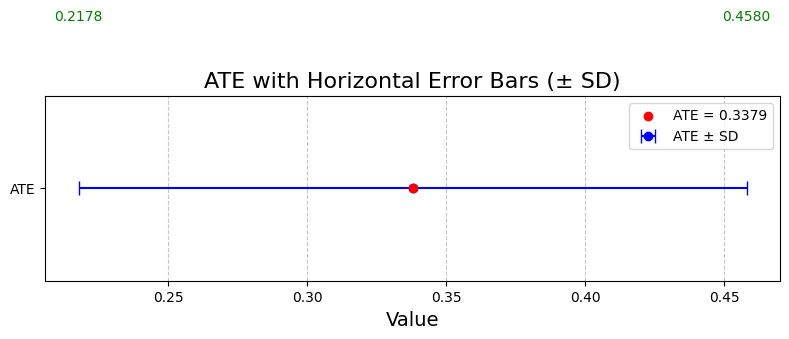

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


ate = np.mean(final_ite_lfm_tarnet)
sd = np.std(final_ite_lfm_tarnet)

# Define the error bounds (ATE ± SD)
lower_bound = ate - sd
upper_bound = ate + sd

# Create the plot
plt.figure(figsize=(8, 4))

# Plot the ATE with horizontal error bars
plt.errorbar(x=ate, y=1, xerr=sd, fmt='o', capsize=5, label='ATE ± SD', color='blue', linestyle='None')

# Highlight the ATE value
plt.scatter(ate, 1, color='red', label=f'ATE = {ate:.4f}', zorder=5)

# Annotate the bounds
plt.text(lower_bound, 1.1, f"{lower_bound:.4f}", horizontalalignment='center', color='green')
plt.text(upper_bound, 1.1, f"{upper_bound:.4f}", horizontalalignment='center', color='green')

# Customizing the plot
plt.title('ATE with Horizontal Error Bars (± SD)', fontsize=16)
plt.yticks([1], ['ATE'])
plt.xlabel('Value', fontsize=14)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()

# Show the plot
plt.show()


#Compare with normal TARNet, where cd496 is y, to be continued??


In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
df = pd.read_csv('/content/ACTG175_data.csv')
#Listwise Deletion
df = df.dropna()

####X
# All binary or close to categorical
c1 = ["hemo", "homo", "drugs", "oprior", "z30", "race", "gender", "str2", "symptom", "karnof"] #Guess Karnofsky score also needs to be standardlized!


c2 = ["age", "wtkg", "cd40", "cd80","preanti"]

# Resclaing c2
scaler = StandardScaler()

# Fit the scaler to the data and transform it
df[c2] = scaler.fit_transform(df[c2])
# Standardize the "karnof" column
df["karnof"] = scaler.fit_transform(df[["karnof"]])

# Combine them into one vector of column names
combined_columns = c1 + c2

x = df[combined_columns]
####Y, also need to be scaled.
cd496_scaled = scaler.fit_transform(df[['cd496']])
y = cd496_scaled.ravel()
#### t
t = df['treat']

In [ ]:
## potential outcome mu_0, mu_1 caluculation
import statsmodels.api as sm

# Define the outcome variable, treatment variable, and covariates
Y = y
T = t
X = x  # Replace with actual column names

# Add a constant to the covariates matrix
X = sm.add_constant(X)

# Fit the regression model
model = sm.OLS(Y, sm.add_constant(pd.concat([T, X], axis=1))).fit()

# Display the summary of the model
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.342
Model:                            OLS   Adj. R-squared:                  0.334
Method:                 Least Squares   F-statistic:                     42.95
Date:                Mon, 13 Jan 2025   Prob (F-statistic):          3.84e-108
Time:                        14:08:00   Log-Likelihood:                -1623.8
No. Observations:                1342   AIC:                             3282.
Df Residuals:                    1325   BIC:                             3370.
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
treat          0.3719      0.053      7.071      0.000       0.269       0.475
const         -0.1641      0.087     -1.893      0.059      -0.334       0.006
hemo           0.0486      0.110      0.444      0.657      -0.166       0.263
homo           0.0144      0.081      0.177      0.859      -0.145       0.173
drugs         -0.0271      0.074     -0.368      0.713      -0.172       0.117
oprior         0.1238      0.162      0.765      0.444      -0.194       0.441
z30           -0.0297      0.116     -0.256      0.798      -0.257       0.198
race          -0.1033      0.056     -1.856      0.064      -0.212       0.006
gender        -0.0095      0.093     -0.102      0.919      -0.191       0.173
str2          -0.1019      0.121     -0.840      0.401      -0.340       0.136
symptom       -0.1219      0.061     -2.010      0.045      -0.241      -0.003
karnof         0.0614      0.023      2.688      0.007       0.017       0.106
age            0.0197      0.024      0.833      0.405      -0.027       0.066
wtkg           0.0405      0.024      1.681      0.093      -0.007       0.088
cd40           0.5430      0.023     23.193      0.000       0.497       0.589
cd80          -0.1044      0.023     -4.494      0.000      -0.150      -0.059
preanti       -0.0571      0.032     -1.774      0.076      -0.120       0.006
==============================================================================
Omnibus:                       88.405   Durbin-Watson:                   1.988
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              184.356
Skew:                           0.425   Prob(JB):                     9.28e-41
Kurtosis:                       4.605   Cond. No.                         16.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
# Predict potential outcomes for treated (mu_1) and control (mu_0)
X1 = sm.add_constant(pd.concat([pd.Series(1, index=X.index, name='T'), X], axis=1))
X0 = sm.add_constant(pd.concat([pd.Series(0, index=X.index, name='T'), X], axis=1))

mu_1 = model.predict(X1)
mu_0 = model.predict(X0)

# Display the estimated potential outcomes
mu_1.head(), mu_0.head()

(0    0.782871
 2   -0.350540
 4    0.719224
 5   -0.456232
 6   -0.408733
 dtype: float64,
 0    0.411016
 2   -0.722395
 4    0.347369
 5   -0.828087
 6   -0.780589
 dtype: float64)

In [ ]:
data3 = {'x': x, 't': t, 'y': y, 'mu_0': mu_0, 'mu_1':mu_1}

In [ ]:
tarnet_model.fit(x=data3['x'],y=yt,
                callbacks=sgd_callbacks,
                validation_split=val_split,
                epochs=300,
                batch_size=batch_size,
                verbose=verbose)
print("Done!")

Epoch 1/300
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
 — ate_err: 0.0005  — cate_err: 0.1205 — cate_nn_err: 1.0730 — ite_sd: 0.1205
ITE values: [[0.5773886 ]
 [0.29673058]
 [0.29066932]
 ...
 [0.46804547]
 [0.11899155]
 [0.36012012]]
Final ITE values stored.
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 42.8938 - regression_loss: 38.1631 - val_loss: 38.9784 - val_regression_loss: 31.0902 - learning_rate: 1.0000e-05
Epoch 2/300
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
 — ate_err: 0.0005  — cate_err: 0.1208 — cate_nn_err: 1.0729 — ite_sd: 0.1208
ITE values: [[0.5779573 ]
 [0.29626858]
 [0.28978753]
 ...
 [0.46856755]
 [0.11811452]
 [0.3596776 ]]
Final ITE values stored.
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 42.8851 - regression_loss: 38.1547 - val_loss: 38.9826 - val_regression_loss: 31.0946 - learning_rate: 1.0000e-05
Epoch 3/300
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
 — ate_err: 0.0005  — cate_err: 0.1212 — cate_nn_err: 1.0711 — ite_sd: 0.1212
ITE values: [[0.5785321 ]
 [0.29

In [ ]:
# Access final ITE values from the callback
full_metrics_callback = next(c for c in sgd_callbacks if isinstance(c, Full_Metrics))
if hasattr(full_metrics_callback, 'final_ite'):
    final_ite_tarnet = full_metrics_callback.final_ite
    print("Final ITE values:", final_ite_tarnet)
else:
    print("Final ITE values are not available.")


Final ITE values: [[0.58981144]
 [0.2778492 ]
 [0.25270146]
 ...
 [0.49257243]
 [0.09264898]
 [0.34080803]]


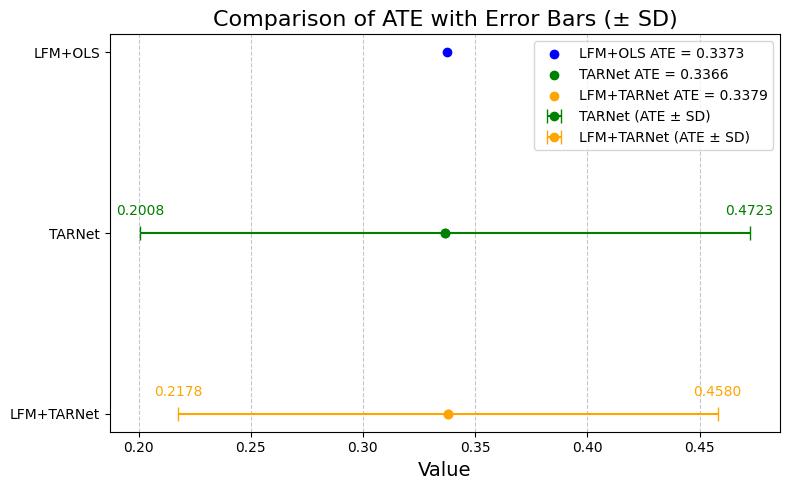

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# Results for LFM+OLS
ate_lfm_ols = 0.3373
#sd_lfm_ols = 0.1

# Results for TARNet
ate_tarnet = np.mean(final_ite_tarnet)
sd_tarnet = np.std(final_ite_tarnet)

# Results for LFM+TARNet
ate_lfm_tarnet = np.mean(final_ite_lfm_tarnet)
sd_lfm_tarnet = np.std(final_ite_lfm_tarnet)

# Create the plot
plt.figure(figsize=(8, 5))

# Plot LFM+OLS ATE with horizontal error bars
#plt.errorbar(x=ate_lfm_ols, y=3, xerr=sd_lfm_ols, fmt='o', capsize=5, color='blue',
             #label='LFM+OLS (ATE ± SD)', linestyle='None')

# Plot TARNet ATE with horizontal error bars
plt.errorbar(x=ate_tarnet, y=2, xerr=sd_tarnet, fmt='o', capsize=5, color='green',
             label='TARNet (ATE ± SD)', linestyle='None')

# Plot LFM+TARNet ATE with horizontal error bars
plt.errorbar(x=ate_lfm_tarnet, y=1, xerr=sd_lfm_tarnet, fmt='o', capsize=5, color='orange',
             label='LFM+TARNet (ATE ± SD)', linestyle='None')

# Highlight ATE values
plt.scatter(ate_lfm_ols, 3, color='blue', label=f'LFM+OLS ATE = {ate_lfm_ols:.4f}', zorder=5)
plt.scatter(ate_tarnet, 2, color='green', label=f'TARNet ATE = {ate_tarnet:.4f}', zorder=5)
plt.scatter(ate_lfm_tarnet, 1, color='orange', label=f'LFM+TARNet ATE = {ate_lfm_tarnet:.4f}', zorder=5)

# Add annotations for bounds
#plt.text(ate_lfm_ols - sd_lfm_ols, 3.1, f"{(ate_lfm_ols - sd_lfm_ols):.4f}", ha='center', color='blue')
#plt.text(ate_lfm_ols + sd_lfm_ols, 3.1, f"{(ate_lfm_ols + sd_lfm_ols):.4f}", ha='center', color='blue')

plt.text(ate_tarnet - sd_tarnet, 2.1, f"{(ate_tarnet - sd_tarnet):.4f}", ha='center', color='green')
plt.text(ate_tarnet + sd_tarnet, 2.1, f"{(ate_tarnet + sd_tarnet):.4f}", ha='center', color='green')

plt.text(ate_lfm_tarnet - sd_lfm_tarnet, 1.1, f"{(ate_lfm_tarnet - sd_lfm_tarnet):.4f}", ha='center', color='orange')
plt.text(ate_lfm_tarnet + sd_lfm_tarnet, 1.1, f"{(ate_lfm_tarnet + sd_lfm_tarnet):.4f}", ha='center', color='orange')

# Customizing the plot
plt.title('Comparison of ATE with Error Bars (± SD)', fontsize=16)
plt.yticks([1, 2, 3], ['LFM+TARNet', 'TARNet', 'LFM+OLS'])
plt.xlabel('Value', fontsize=14)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()

# Show the plot
plt.show()


# some histograms

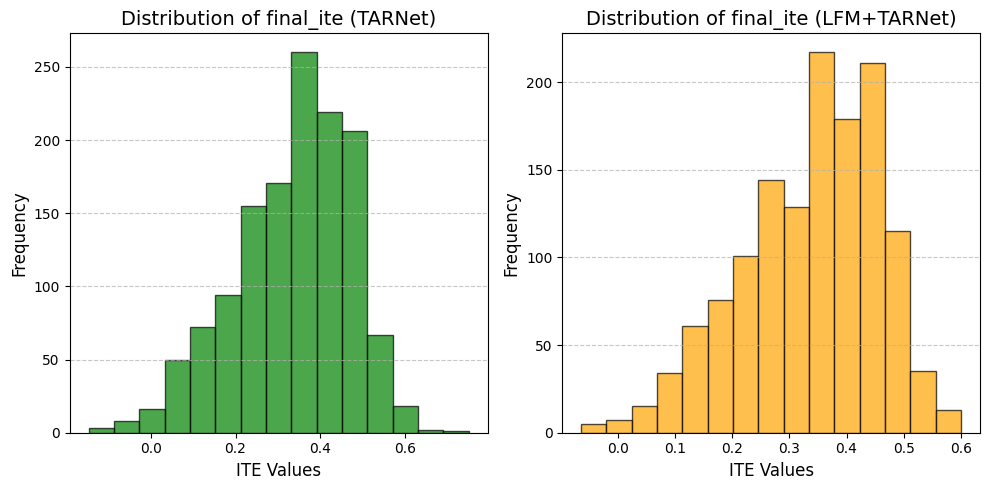

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Histogram for TARNet final_ite
plt.subplot(1, 2, 1)
plt.hist(final_ite_tarnet, bins=15, color='green', alpha=0.7, edgecolor='black')
plt.title('Distribution of final_ite (TARNet)', fontsize=14)
plt.xlabel('ITE Values', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Histogram for LFM+TARNet final_ite
plt.subplot(1, 2, 2)
plt.hist(final_ite_lfm_tarnet, bins=15, color='orange', alpha=0.7, edgecolor='black')
plt.title('Distribution of final_ite (LFM+TARNet)', fontsize=14)
plt.xlabel('ITE Values', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adjust layout and show
plt.tight_layout()
plt.show()


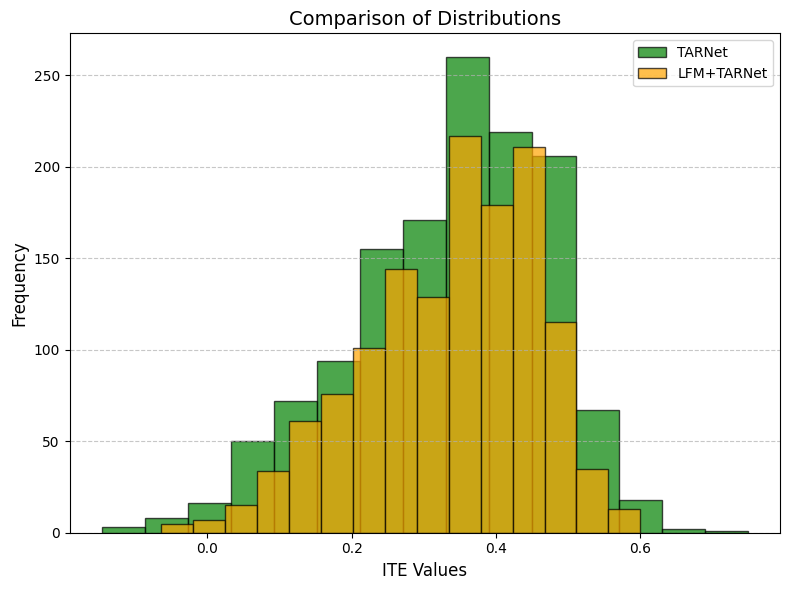

In [ ]:
plt.figure(figsize=(8, 6))

# Overlay the histograms
plt.hist(final_ite_tarnet, bins=15, alpha=0.7, color='green', label='TARNet', edgecolor='black')
plt.hist(final_ite_lfm_tarnet, bins=15, alpha=0.7, color='orange', label='LFM+TARNet', edgecolor='black')

# Add titles and labels
plt.title('Comparison of Distributions', fontsize=14)
plt.xlabel('ITE Values', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Show plot
plt.show()


# HyperParamater Tuning

In [ ]:
# Install Keras Tuner
!pip install keras-tuner==1.0.4

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 44.0 MB/s eta 0:00:00


In [ ]:
import keras_tuner as kt
from keras_tuner.tuners import RandomSearch
from tensorflow.keras.optimizers import SGD
def make_hypertarnet(hp):
    """
    Neural net predictive model. The dragon has three heads.
    :param input_dim:
    :param reg:
    :return:
    """
    # hp.Choice takes hyperparam name, list of options, and default
    reg_l2=hp.Choice('l2',[.1,.01,.001],default=.01)
    input_dim=15
    inputs = Input(shape=(input_dim,), name='input')

    # representation
    rep_units = hp.Choice('rep_units', [50,100,200],default=200)
    phi = Dense(units=rep_units, activation='elu', kernel_initializer='RandomNormal',name='phi_1')(inputs)
    for i in range(hp.Int('rep_layers', 1, 2, default=1)):
      #pretty nifty way to dynamically add more layers!
      phi = Dense(units=rep_units, activation='elu', kernel_initializer='RandomNormal',name='phi_'+str(i+2))(phi)

    # HYPOTHESIS
    hyp_units = hp.Choice('hyp_units', [20,50,100,200],default=100)
    y0_hidden = Dense(units=hyp_units, activation='elu', kernel_regularizer=regularizers.l2(reg_l2),name='y0_hidden_1')(phi)
    y1_hidden = Dense(units=hyp_units, activation='elu', kernel_regularizer=regularizers.l2(reg_l2),name='y1_hidden_1')(phi)
    for i in range(hp.Int('hyp_layers', 1, 3, default=2)):
      y0_hidden = Dense(units=hyp_units, activation='elu', kernel_regularizer=regularizers.l2(reg_l2),name='y0_hidden_'+str(i+2))(y0_hidden)
      y1_hidden = Dense(units=hyp_units, activation='elu', kernel_regularizer=regularizers.l2(reg_l2),name='y1_hidden_'+str(i+2))(y1_hidden)

    # OUTPUT
    y0_predictions = Dense(units=1, activation=None, kernel_regularizer=regularizers.l2(reg_l2), name='y0_predictions')(y0_hidden)
    y1_predictions = Dense(units=1, activation=None, kernel_regularizer=regularizers.l2(reg_l2), name='y1_predictions')(y1_hidden)

    concat_pred = Concatenate(1)([y0_predictions, y1_predictions,phi])
    model = Model(inputs=inputs, outputs=concat_pred)

    sgd_lr = 1e-5
    momentum = 0.9

    optimizer=SGD(learning_rate=sgd_lr, momentum=momentum, nesterov=True)

    model.compile(optimizer=SGD(learning_rate=sgd_lr, momentum=momentum, nesterov=True),
                      loss=regression_loss,
                 metrics=regression_loss)

    return model

In [ ]:
from keras_tuner.engine import tuner_utils
from tensorboard.plugins.hparams import api as hparams_api
!rm -rf my_dir

class TarNetTuner(kt.Tuner):

  def run_trial(self, trial,dataset,*fit_args, **fit_kwargs):
      # *args and **kwargs in Python are positional (list) and keyword (dict) arguments
      verbose = fit_kwargs['verbose']

      log_dir=self.project_dir+'/trial_'+trial.trial_id
      hp = trial.hyperparameters

      batch_size = hp.Int('batch_size', 128, 256, step=64, default=128)
      stopping_patience=hp.Int('batch_size', 5, 15, step=5, default=5)

      #some of this hacky code will hopefully go away as Keras Tuner get's more polished
      hparams = tuner_utils.convert_hyperparams_to_hparams(trial.hyperparameters)
      file_writer = tf.summary.create_file_writer(log_dir + "/metrics")
      file_writer.set_as_default()

      tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)
      hparams_callback = hparams_api.KerasCallback(
                        writer=log_dir,
                        hparams=hparams,
                        #I prepend trial_ here to get it to save nicely. Hopefully will be fixed in future version of KT.
                        trial_id='trial_'+trial.trial_id)
      metrics_callback=Full_Metrics(dataset,verbose=verbose)
      callbacks = [
              TerminateOnNaN(),
              EarlyStopping(monitor='val_loss', patience=stopping_patience, min_delta=0.0001),
              ReduceLROnPlateau(monitor='loss', factor=0.5, patience=5, verbose=verbose, mode='auto',
                                min_delta=0, cooldown=0, min_lr=0),
              metrics_callback,
              tensorboard_callback,
              hparams_callback
          ]


      model = self.hypermodel.build(hp)
      model.fit(x=fit_args[0],y=fit_args[1],
                 callbacks=callbacks,
                  validation_split=fit_kwargs['validation_split'],
                  epochs=fit_kwargs['epochs'],
                  batch_size=batch_size, verbose=verbose)

      #give the metric to the hyperparameter optimization algorithm
      concat_pred=model.predict(data['x'])
      pehe_nn=metrics_callback.PEHEnn(concat_pred)
      self.oracle.update_trial(trial.trial_id, {'cate_nn_err': tf.sqrt(pehe_nn)})
      self.save_model(trial.trial_id, model)


In [ ]:
tuner = TarNetTuner(
    #the oracle is the hyperoptimization algorithm
    oracle=kt.oracles.BayesianOptimization(
        objective=kt.Objective('cate_nn_err', 'min'),
        max_trials=10, #were trying to keep this quick for you.
        #You probably want to do as many trials as your resources allow if you see variance between runs
        seed=0
),
        directory='my_dir',
        project_name='helloworld',
    hypermodel=make_hypertarnet
    )
tuner.search(data, data['x'],yt, epochs=300,validation_split=.2,verbose=2)

best_trial=tuner.oracle.get_best_trials(num_trials=1)[0]
print("BEST TRIAL ID:",best_trial.trial_id)
best_model=tuner.load_model(best_trial)

Trial 10 Complete [00h 01m 28s]
cate_nn_err: 1.077760934829712

Best cate_nn_err So Far: 1.0581810474395752
Total elapsed time: 00h 12m 39s
BEST TRIAL ID: a3d6af83a2ddde07dd47d061144d0364


In [ ]:
# Save the best model
best_model.save('/content/best_model.keras')

In [ ]:
# Print the hyperparameters of the best trial
best_hyperparameters = best_trial.hyperparameters
print("Best Hyperparameters:")
for key, value in best_hyperparameters.values.items():
    print(f"{key}: {value}")

Best Hyperparameters:
l2: 0.01
rep_units: 50
rep_layers: 2
hyp_units: 20
hyp_layers: 1
batch_size: 128


In [ ]:
best_model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input (InputLayer)          [(None, 15)]                 0         []                            
                                                                                                  
 phi_1 (Dense)               (None, 50)                   800       ['input[0][0]']               
                                                                                                  
 phi_2 (Dense)               (None, 50)                   2550      ['phi_1[0][0]']               
                                                                                                  
 phi_3 (Dense)               (None, 50)                   2550      ['phi_2[0][0]']               
                                                                                              

In [ ]:
from tensorflow.keras.models import load_model

# Load the saved model
model = load_model('best_model.keras')

# Display the model architecture
model.summary()

TypeError: Could not locate function 'regression_loss'. Make sure custom classes are decorated with `@keras.saving.register_keras_serializable()`. Full object config: {'module': 'builtins', 'class_name': 'function', 'config': 'regression_loss', 'registered_name': 'function', 'shared_object_id': 133185801036144}

In [ ]:
%tensorboard --logdir my_dir/helloworld/

<IPython.core.display.Javascript object>